# Forecasting the Dec 2022 – Jan 2023 West Coast Flood with ECMWF **AIFS v2** vs **ERA5** — a lead-time sweep

This notebook reuses the **AIFS v2** pipeline from `HeatWaves.ipynb` (ECMWF's Artificial Intelligence
Forecasting System v2, run via NVIDIA **earth2studio**, initialized from **ERA5**) but forecasts
**precipitation** instead of temperature, for the **New Year atmospheric river** that flooded the
Sacramento area on **Dec 31 2022 – Jan 1 2023** (the opening act of the 2022–2023 West Coast flood season).

**Lead-time experiment.** The flood is a *fixed target*. We forecast it from **three different lead
times — 3, 7, and 10 days** — by initializing three separate AIFS v2 runs:

| lead | init (00Z) | runs through |
|------|------------|--------------|
| 3 d  | 2022-12-28 | 2023-01-02 |
| 7 d  | 2022-12-24 | 2023-01-02 |
| 10 d | 2022-12-21 | 2023-01-02 |

All three are valid over the same Dec 31 – Jan 1 window, so each is verified against the **same ERA5
truth**. The expected story: the 3-day forecast tracks ERA5 best, the 10-day worst — i.e. *how far
ahead could AIFS v2 see this atmospheric river?*

**Precipitation accumulation.** AIFS v2's precip output id is **`tp06`** — *6-hour accumulated* total
precipitation (metres). A daily total is the sum of that day's four 6-h steps (× 1000 → mm). ERA5's
`total_precipitation` is *hourly accumulation* (metres); a daily total is the sum of the 24 hourly
values (× 1000 → mm). Because we compare **accumulated totals**, the comparison is exact, without the
afternoon-peak sampling caveat the heat-wave notebook had.

In [ ]:
# --- Environment (must be set BEFORE importing torch / earth2studio) ---
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["CUFILE_ENV_PATH_JSON"] = "/dev/null"

import gc, warnings
from pathlib import Path
from collections import OrderedDict
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from aifs2_era5 import patch_cds_lexicon_for_aifs2, ZERO_FILL_WAVE_VARS
from earth2studio.data import CDS
from earth2studio.io import ZarrBackend
from earth2studio.run import deterministic
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__)

PROJECT  = Path("/home/jovyan/West-Coast")
DATA_DIR = PROJECT / "data"
FIG_DIR  = PROJECT / "figures"
for d in (DATA_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- Event & lead-time configuration ---
# Anchor event: the New Year atmospheric river (Sacramento-area flooding).
EVENT_START = np.datetime64("2022-12-31")           # AR core day 1
EVENT_END   = np.datetime64("2023-01-01")           # AR core day 2
TARGET_END  = np.datetime64("2023-01-02T00:00:00")  # run every forecast at least through here
EVENT_DAYS  = np.array([EVENT_START, EVENT_END])     # days summed for the "event total"

LEAD_DAYS = [3, 7, 10]                                # days before the event we initialize
def init_for_lead(lead):
    return EVENT_START - np.timedelta64(int(lead), "D")
def nsteps_for_init(init):
    return int((TARGET_END - np.datetime64(init)) / np.timedelta64(6, "h"))

PRECIP_VAR = "tp06"   # AIFS v2 output id: 6-hour ACCUMULATED total precip (m). Verified in cell below.

# Region (used only to crop the maps). lon given in BOTH 0-360 (native) and -180..180 (plotting).
REGIONS = {
    "WEST_COAST": dict(lat=(32, 47), lon360=(232, 247), lon180=(-128, -113)),
}

# Flood-affected locations: name -> (lat, lon in -180..180). Cosumnes R. @ Wilton is where the
# New Year AR breached levees and flooded Highway 99 (~Dec 31 2022).
LOCATIONS = {
    "San Francisco":        (37.77, -122.42),
    "Sacramento":           (38.58, -121.49),
    "Oakland":              (37.80, -122.27),
    "Santa Rosa":           (38.44, -122.71),
    "Cosumnes R. (Wilton)": (38.40, -121.24),
}
# short codes for compact table / plot labels
SHORT = {"San Francisco": "SF", "Sacramento": "SAC", "Oakland": "OAK",
         "Santa Rosa": "SRO", "Cosumnes R. (Wilton)": "COS"}

THRESHOLDS_MM = {"heavy (25mm)": 25.0, "extreme (50mm)": 50.0}

for L in LEAD_DAYS:
    init = init_for_lead(L)
    print(f"lead {L:2d} d  |  init {str(init)[:10]} 00Z  |  "
          f"{nsteps_for_init(init)} steps x 6h  ->  {str(TARGET_END)[:10]}")

## 1 · Load AIFS v2 and patch the ERA5/CDS lexicon

Identical to `HeatWaves.ipynb` §1: `patch_cds_lexicon_for_aifs2()` teaches earth2studio's CDS source
the AIFS-v2 inputs it is otherwise missing (see that notebook for the detail). We additionally confirm
that the precipitation output id `tp06` is one of the model's output variables.

In [2]:
zeroed = patch_cds_lexicon_for_aifs2()
print("zero-filled wave inputs:", zeroed)

from earth2studio.models.px import AIFS2
from earth2studio.lexicon import CDSLexicon

model = AIFS2.load_model(AIFS2.load_default_package()).to(DEVICE)
ic = model.input_coords()
try:
    out_vars = list(map(str, model.output_coords(ic)["variable"]))
except Exception as exc:
    out_vars = list(map(str, ic["variable"]))     # AIFS outputs the same state it ingests
    print("note: falling back to input vars for the output check:", exc)

print("AIFS v2 loaded | input lead_time:", ic["lead_time"], "| n inputs:", len(ic["variable"]))
print("precip output id:", PRECIP_VAR, "| present:", PRECIP_VAR in out_vars,
      "| precip-like outputs:", [v for v in out_vars if "tp" in v or "cp" in v])
assert PRECIP_VAR in out_vars, f"{PRECIP_VAR} is not an AIFS v2 output variable"

missing = sorted(set(map(str, ic["variable"])) - set(CDSLexicon.VOCAB.keys()))
print("CDS lexicon gap after patch:", missing if missing else "none (ready to initialize)")

zero-filled wave inputs: ['swh', 'mwp', 'cdww', 'cos_mwd', 'sin_mwd', 'h1012', 'h1214', 'h1417', 'h1721', 'h2125', 'h2530'] parsing error, invalid json config /dev/null
 failed to load user config: /dev/null Invalid argument
 cuFile configuration load error
 cuFile initialization failed
CuPy distance computation test failed with error: cuVS >= 24.12 or pylibraft < 24.12 should be installed to use this featureAIFS v2 loaded | input lead_time: [-6  0] | n inputs: 92
precip output id: tp06 | present: True | precip-like outputs: ['cp06', 'tp06']
CDS lexicon gap after patch: none (ready to initialize)

## 2 · Run the lead-time sweep — three AIFS v2 forecasts of the same flood

`run_forecast()` is the same function as in `HeatWaves.ipynb` (deterministic AIFS-v2 integration from
an ERA5 init), with one tweak: the output variable is folded into the cache filename so these
precipitation runs never collide with the heat-wave `t2m` caches. We loop it over the three init
dates. **The first run of each init downloads a full 92-variable ERA5 initial state from the CDS
(slow), then caches it** — re-runs are fast.

In [3]:
def run_forecast(init_time, nsteps, variables, overwrite=False):
    '''Deterministic global AIFS-v2 forecast from ERA5 init -> path to a Zarr store.
    Cache key includes the (first) output variable so precip runs never collide with t2m caches.'''
    tag  = np.datetime_as_string(np.datetime64(init_time), unit="D").replace("-", "")
    vtag = str(np.asarray(variables)[0])
    out_path = DATA_DIR / f"aifs_forecast_init{tag}_{vtag}.zarr"
    if out_path.exists() and not overwrite:
        print("using cached forecast:", out_path)
        return out_path
    deterministic(
        time=[np.datetime64(init_time)],
        nsteps=nsteps,
        prognostic=model,
        data=CDS(cache=True),
        io=ZarrBackend(str(out_path), backend_kwargs={"overwrite": True}),
        output_coords=OrderedDict({"variable": np.asarray(variables)}),
        device=DEVICE,
    )
    return out_path

fc_paths = {}
for L in LEAD_DAYS:
    init = init_for_lead(L)
    print(f"\n--- lead {L} d  (init {str(init)[:10]} 00Z, {nsteps_for_init(init)} steps) ---")
    fc_paths[L] = run_forecast(init, nsteps=nsteps_for_init(init),
                               variables=np.array([PRECIP_VAR]))
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nforecasts:")
for L, p in fc_paths.items():
    print(f"  lead {L:2d} d -> {p}")


--- lead 3 d  (init 2022-12-28 00Z, 20 steps) ---2026-06-08 21:34:15.376 | INFO     | earth2studio.run:deterministic:78 - Running simple workflow!
2026-06-08 21:34:15.377 | INFO     | earth2studio.run:deterministic:85 - Inference device: cuda
2026-06-08 21:34:15.380 | INFO     | earth2studio.data.cds:_fetch_process:177 - Fetching CDS grib file for variable: 10m_u_component_of_wind at 2022-12-27 18:00:00 with 1 levels2026-06-08 21:34:16.393 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:21b8a994-9b05-486c-8f00-c551461e786e, state: accepted2026-06-08 21:34:18.583 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:21b8a994-9b05-486c-8f00-c551461e786e, state: accepted2026-06-08 21:34:20.766 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:21b8a994-9b05-486c-8f00-c551461e786e, state: accepted2026-06-08 21:34:22.962 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:21b8a994-9b0

2026-06-08 21:34:38.923 | INFO     | earth2studio.data.cds:_fetch_process:177 - Fetching CDS grib file for variable: 10m_v_component_of_wind at 2022-12-27 18:00:00 with 1 levels2026-06-08 21:34:39.903 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:eb5a7562-caa3-4b17-bc08-720bfe79a19f, state: accepted2026-06-08 21:34:42.104 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:eb5a7562-caa3-4b17-bc08-720bfe79a19f, state: accepted2026-06-08 21:34:44.292 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:eb5a7562-caa3-4b17-bc08-720bfe79a19f, state: accepted2026-06-08 21:34:46.459 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:eb5a7562-caa3-4b17-bc08-720bfe79a19f, state: accepted2026-06-08 21:34:48.636 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:eb5a7562-caa3-4b17-bc08-720bfe79a19f, state: accepted2026-06-08 21:34:50.809 | DEBUG    | earth2studi

2026-06-08 21:35:07.139 | INFO     | earth2studio.data.cds:_fetch_process:177 - Fetching CDS grib file for variable: 2m_dewpoint_temperature at 2022-12-27 18:00:00 with 1 levels2026-06-08 21:35:07.954 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:26f8cf2a-beb6-40c6-9af4-ec9b0bfafa0c, state: accepted2026-06-08 21:35:10.124 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:26f8cf2a-beb6-40c6-9af4-ec9b0bfafa0c, state: accepted2026-06-08 21:35:12.434 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:26f8cf2a-beb6-40c6-9af4-ec9b0bfafa0c, state: accepted2026-06-08 21:35:14.608 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:26f8cf2a-beb6-40c6-9af4-ec9b0bfafa0c, state: accepted2026-06-08 21:35:18.849 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:26f8cf2a-beb6-40c6-9af4-ec9b0bfafa0c, state: running
2026-06-08 21:35:18.849 | DEBUG    | earth2studi

2026-06-08 21:35:29.298 | INFO     | earth2studio.data.cds:_fetch_process:177 - Fetching CDS grib file for variable: 2m_temperature at 2022-12-27 18:00:00 with 12 levels2026-06-08 21:35:30.087 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:fbd98b78-3617-406c-ac9e-16fb044854bc, state: accepted2026-06-08 21:35:32.501 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:fbd98b78-3617-406c-ac9e-16fb044854bc, state: accepted2026-06-08 21:35:34.668 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:fbd98b78-3617-406c-ac9e-16fb044854bc, state: accepted2026-06-08 21:35:37.090 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:fbd98b78-3617-406c-ac9e-16fb044854bc, state: accepted2026-06-08 21:35:39.367 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:fbd98b78-3617-406c-ac9e-16fb044854bc, state: accepted2026-06-08 21:35:41.536 | DEBUG    | earth2studio.data.c

2026-06-08 21:35:55.773 | INFO     | earth2studio.data.cds:_fetch_process:177 - Fetching CDS grib file for variable: mean_sea_level_pressure at 2022-12-27 18:00:00 with 1 levels2026-06-08 21:35:56.673 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:23b04929-be8f-419f-9212-c31a4def592e, state: accepted2026-06-08 21:35:58.852 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:23b04929-be8f-419f-9212-c31a4def592e, state: accepted2026-06-08 21:36:01.024 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:23b04929-be8f-419f-9212-c31a4def592e, state: accepted2026-06-08 21:36:03.191 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:23b04929-be8f-419f-9212-c31a4def592e, state: accepted2026-06-08 21:36:05.370 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:23b04929-be8f-419f-9212-c31a4def592e, state: running
2026-06-08 21:36:05.371 | DEBUG    | earth2studi

2026-06-08 21:36:17.012 | INFO     | earth2studio.data.cds:_fetch_process:177 - Fetching CDS grib file for variable: specific_humidity at 2022-12-27 18:00:00 with 12 levels2026-06-08 21:36:18.124 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:cd6e11fe-5609-4814-be4a-d96172e87fa8, state: accepted2026-06-08 21:36:20.298 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:cd6e11fe-5609-4814-be4a-d96172e87fa8, state: accepted2026-06-08 21:36:22.483 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:cd6e11fe-5609-4814-be4a-d96172e87fa8, state: accepted2026-06-08 21:36:28.974 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:cd6e11fe-5609-4814-be4a-d96172e87fa8, state: accepted2026-06-08 21:36:31.158 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:cd6e11fe-5609-4814-be4a-d96172e87fa8, state: running
2026-06-08 21:36:31.158 | DEBUG    | earth2studio.dat

... (105 outputs left out)

2026-06-08 22:19:45.216 | INFO     | earth2studio.data.cds:_fetch_process:177 - Fetching CDS grib file for variable: geopotential at 2022-12-21 00:00:00 with 14 levels2026-06-08 22:19:45.824 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:548d5216-2e06-464d-bc68-b0b93e2fb24a, state: accepted2026-06-08 22:19:48.405 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:548d5216-2e06-464d-bc68-b0b93e2fb24a, state: accepted2026-06-08 22:19:50.573 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:548d5216-2e06-464d-bc68-b0b93e2fb24a, state: accepted2026-06-08 22:19:52.757 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:548d5216-2e06-464d-bc68-b0b93e2fb24a, state: accepted2026-06-08 22:19:54.925 | DEBUG    | earth2studio.data.cds:_download_cds_grib_cached:325 - Request ID:548d5216-2e06-464d-bc68-b0b93e2fb24a, state: running
2026-06-08 22:19:54.925 | DEBUG    | earth2studio.data.cds

2026-06-08 22:20:10.433 | SUCCESS  | earth2studio.run:deterministic:109 - Fetched data from CDS2026-06-08 22:20:10.636 | INFO     | earth2studio.run:deterministic:139 - Inference starting!

Running inference: 100%|██████████| 49/49 [00:38<00:00,  1.27it/s]

2026-06-08 22:20:49.182 | SUCCESS  | earth2studio.run:deterministic:151 - 
Inference complete
forecasts:
  lead  3 d -> /home/jovyan/West-Coast/data/aifs_forecast_init20221228_tp06.zarr
  lead  7 d -> /home/jovyan/West-Coast/data/aifs_forecast_init20221224_tp06.zarr
  lead 10 d -> /home/jovyan/West-Coast/data/aifs_forecast_init20221221_tp06.zarr

## 3 · Load the forecasts and fetch ERA5 precipitation truth

We read each forecast's `tp06`, attach a **valid-time** axis (`init + lead`), convert m → mm, and sum
the 6-hourly accumulations into **daily totals**. ERA5 truth is pulled from the CDS as **hourly**
`total_precipitation` over a West-Coast area subset and summed to daily totals (mm). Both are on the
identical 0.25° grid, so no regridding is needed.

In [8]:
def load_forecast_precip(path, init_time, var=PRECIP_VAR):
    '''Open a forecast Zarr -> 6-hourly ACCUMULATED precip (valid_time, lat, lon) in mm/6h.'''
    ds = xr.open_zarr(str(path))
    da = ds[var]
    for d in ("batch", "time"):                       # squeeze singleton init dims
        if d in da.dims:
            da = da.isel({d: 0}, drop=True)
    valid = np.datetime64(init_time) + da["lead_time"].values
    da = da.assign_coords(lead_time=valid).rename(lead_time="valid_time")
    da = (da * 1000.0).clip(min=0.0)                  # m -> mm, guard tiny negatives
    return da.assign_attrs(units="mm")

def daily_total(da, time_name="valid_time"):
    '''6-hourly accumulated precip -> daily TOTAL (mm/day); renames the day axis to 'day'.'''
    out = da.resample({time_name: "1D"}).sum()
    return out.rename({time_name: "day"})

# AIFS daily-total precip, one field per lead time
aifs_daily = {}
for L in LEAD_DAYS:
    da = load_forecast_precip(fc_paths[L], init_for_lead(L))
    aifs_daily[L] = daily_total(da)
    d0, d1 = aifs_daily[L]["day"].values[[0, -1]]
    print(f"lead {L:2d} d AIFS daily precip: {dict(aifs_daily[L].sizes)}  "
          f"{str(d0)[:10]} -> {str(d1)[:10]}")

WC = REGIONS["WEST_COAST"]
# ERA5 area subset (1 deg wider than the plot bbox): [North, West, South, East] in -180..180
ERA5_AREA = [WC["lat"][1] + 1, WC["lon180"][0] - 1, WC["lat"][0] - 1, WC["lon180"][1] + 1]

def fetch_era5_precip(days, area, cache_path):
    '''ERA5 daily-total precip (mm) over `area` for the given UTC days: hourly
    total_precipitation summed per day. One batched CDS request per month, cached.'''
    cache_path = Path(cache_path)
    if cache_path.exists():
        return xr.open_dataarray(cache_path)
    import cdsapi
    days = [np.datetime64(d, "D") for d in days]
    by_month = {}
    for d in days:
        ym = (str(d)[:4], str(d)[5:7])
        by_month.setdefault(ym, set()).add(str(d)[8:10])
    client = cdsapi.Client()
    parts = []
    for (yr, mo), dnums in sorted(by_month.items()):
        tmp = cache_path.with_name(f"_era5_tp_{yr}{mo}.nc")
        if not tmp.exists():
            client.retrieve("reanalysis-era5-single-levels",
                {"product_type": "reanalysis", "variable": "total_precipitation",
                 "year": yr, "month": mo, "day": sorted(dnums),
                 "time": [f"{h:02d}:00" for h in range(24)],
                 "area": area, "format": "netcdf"}, str(tmp))
        d = xr.open_dataset(tmp)["tp"].drop_vars(["number", "expver"], errors="ignore")
        d = d.rename({"latitude": "lat", "longitude": "lon"})
        tname = "valid_time" if "valid_time" in d.dims else ("time" if "time" in d.dims else list(d.dims)[0])
        parts.append(d.rename({tname: "valid_time"}))
    da = xr.concat(parts, dim="valid_time") if len(parts) > 1 else parts[0]
    da = da.assign_coords(lon=(da["lon"] % 360)).sortby("lon")   # -> 0-360, match AIFS
    da = (da * 1000.0).clip(min=0.0)                              # m -> mm
    da = da.resample(valid_time="1D").sum().rename(valid_time="day")
    da.name = "tp"
    da = da.assign_attrs(units="mm")
    da.to_netcdf(cache_path)
    return da

# union of all forecast days across leads (the 10-day lead spans the most)
all_days = np.unique(np.concatenate([aifs_daily[L]["day"].values for L in LEAD_DAYS]))
era5_daily = fetch_era5_precip(all_days, ERA5_AREA, DATA_DIR / "era5_tp_westcoast.nc")
print("ERA5 daily precip:", dict(era5_daily.sizes),
      "|", str(era5_daily["day"].values[0])[:10], "->", str(era5_daily["day"].values[-1])[:10])

lead  3 d AIFS daily precip: {'day': 6, 'lat': 721, 'lon': 1440}  2022-12-28 -> 2023-01-02
lead  7 d AIFS daily precip: {'day': 10, 'lat': 721, 'lon': 1440}  2022-12-24 -> 2023-01-02
lead 10 d AIFS daily precip: {'day': 13, 'lat': 721, 'lon': 1440}  2022-12-21 -> 2023-01-02

ERA5 daily precip: {'day': 13, 'lat': 69, 'lon': 69} | 2022-12-21 -> 2023-01-02

## 4 · Helpers: regional cropping, longitude conversion, area-weighting, error metrics

`crop_bbox` and `to_180` are reused verbatim from `HeatWaves.ipynb`. `at_point` and `to_region_pair`
are small additions for the precip tables and for grid-/day-matching each lead's forecast to ERA5.

In [ ]:
def crop_bbox(da, lat_range, lon360_range, lat_name="lat", lon_name="lon"):
    '''Slice a DataArray (lon in 0-360, lat descending) to a bbox given in 0-360 lon.'''
    lo_lat, hi_lat = min(lat_range), max(lat_range)
    da = da.sel({lat_name: slice(hi_lat, lo_lat)})         # lat is descending
    lo_lon, hi_lon = lon360_range
    if lo_lon <= hi_lon:
        return da.sel({lon_name: slice(lo_lon, hi_lon)})
    lon = da[lon_name]
    return da.sel({lon_name: lon[(lon >= lo_lon) | (lon <= hi_lon)]})   # dateline wrap

def to_180(da, lon_name="lon"):
    '''Convert lon 0-360 -> -180..180 and sort (for cartopy plotting).'''
    da = da.assign_coords({lon_name: (((da[lon_name] + 180) % 360) - 180)})
    return da.sortby(lon_name)

def at_point(da, lat, lon):
    '''EXACT value at the single 0.25 deg grid cell nearest a point (lon in -180..180).
    No averaging - this is the model's grid-box value containing the location.'''
    return da.sel(lat=lat, lon=lon % 360, method="nearest")

def to_region_pair(aifs_field, era5_field, region):
    '''Crop AIFS + ERA5 daily fields to a region, put ERA5 on the AIFS grid, keep common days.
    Used only for the spatial maps.'''
    info = REGIONS[region]
    a = crop_bbox(aifs_field, info["lat"], info["lon360"])
    e = crop_bbox(era5_field, info["lat"], info["lon360"])
    e = e.reindex(lat=a["lat"], lon=a["lon"], method="nearest")     # exact same 0.25 deg grid
    common = np.intersect1d(a["day"].values, e["day"].values)
    return a.sel(day=common), e.sel(day=common)

# West Coast crops for the maps: aifs_wc[L] and the matching era5_wc[L] (same grid; days = lead L)
aifs_wc, era5_wc = {}, {}
for L in LEAD_DAYS:
    aifs_wc[L], era5_wc[L] = to_region_pair(aifs_daily[L], era5_daily, "WEST_COAST")
print("West Coast map grid:", dict(aifs_wc[LEAD_DAYS[0]].sizes))

## 5 · Per-day accumulated-precipitation tables — one per lead time

For each lead time, a table of **total precipitation accumulated per day** (mm) at each affected
location — the four cities plus the **Cosumnes River @ Wilton** — read from the **exact nearest
0.25° grid cell** (no spatial averaging; this is the model's grid-box value containing the site, not a
rain-gauge point). Columns are grouped by location into AIFS v2 vs ERA5, and the event days
(Dec 31 + Jan 1) are summed in the bottom **EVENT TOTAL** row.

In [ ]:
try:
    from IPython.display import display
except Exception:
    display = print

for L in LEAD_DAYS:
    a = aifs_daily[L]                 # global AIFS daily totals for this lead
    days = a["day"].values
    era5_days = set(era5_daily["day"].values)
    cols = {}
    for name, (lat, lon) in LOCATIONS.items():
        code = SHORT[name]
        a_loc = at_point(a, lat, lon)
        e_loc = at_point(era5_daily, lat, lon)
        cols[(code, "AIFS")] = [round(float(a_loc.sel(day=d)), 1) for d in days]
        cols[(code, "ERA5")] = [round(float(e_loc.sel(day=d)), 1) if d in era5_days else np.nan
                                for d in days]
    df = pd.DataFrame(cols, index=[str(d)[:10] for d in days])
    df.columns = pd.MultiIndex.from_tuples(df.columns, names=["location", "source"])
    df.index.name = "valid day (UTC)"

    # event-total row (Dec 31 + Jan 1)
    evmask = np.isin(np.array(df.index), np.array([str(x)[:10] for x in EVENT_DAYS]))
    ev = df[evmask].sum(axis=0).round(1)
    ev.name = "EVENT TOTAL"
    df_show = pd.concat([df, ev.to_frame().T])

    print(f"\n===== Lead {L} d  |  init {str(init_for_lead(L))[:10]} 00Z  |  "
          f"daily TOTAL precip (mm), exact grid cell per location =====")
    display(df_show)

## 6 · Event-total precipitation maps by lead time

Event-total precip (Dec 31 2022 + Jan 1 2023) over the West Coast: rows are the three lead times, and
columns are **AIFS v2 forecast**, **ERA5 truth**, and **AIFS − ERA5**. As lead time shrinks from 10 to
3 days, the AIFS panel should converge toward ERA5 and the difference panel should fade.

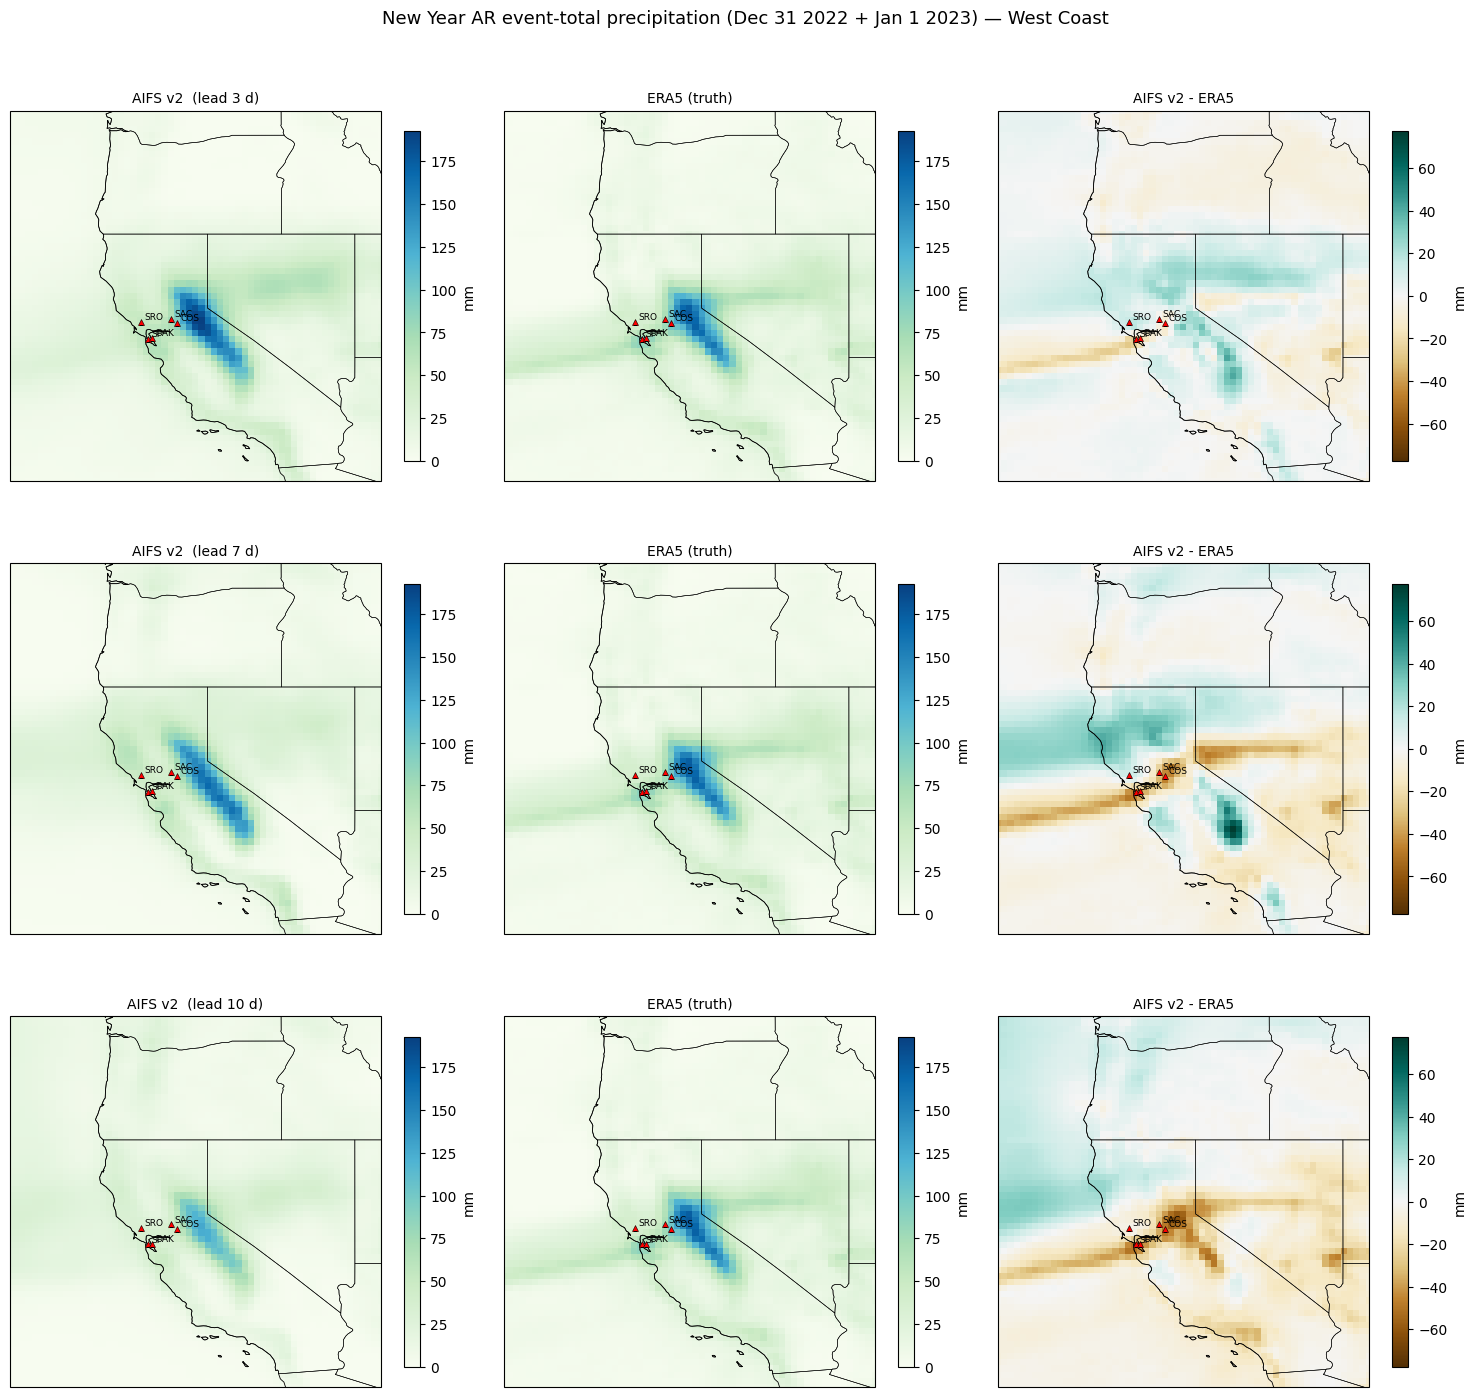

In [24]:
def event_total(field):
    '''Sum daily-total precip over the event days (robust to datetime resolution).'''
    days = field["day"].values.astype("datetime64[D]")
    sel = np.isin(days, EVENT_DAYS.astype("datetime64[D]"))
    return field.isel(day=np.where(sel)[0]).sum("day")

ev_aifs = {L: to_180(event_total(aifs_wc[L])) for L in LEAD_DAYS}
ev_era5 = {L: to_180(event_total(era5_wc[L])) for L in LEAD_DAYS}

vmax = max(float(max(ev_aifs[L].max(), ev_era5[L].max())) for L in LEAD_DAYS)
dmax = max(float(np.nanmax(np.abs((ev_aifs[L] - ev_era5[L]).values))) for L in LEAD_DAYS) or 1.0
info = REGIONS["WEST_COAST"]

fig, axes = plt.subplots(len(LEAD_DAYS), 3, figsize=(15, 4.8 * len(LEAD_DAYS)),
                         subplot_kw={"projection": ccrs.PlateCarree()})
for r, L in enumerate(LEAD_DAYS):
    a, e = ev_aifs[L], ev_era5[L]
    diff = a - e
    panels = [(f"AIFS v2  (lead {L} d)", a, "GnBu", 0, vmax),
              ("ERA5 (truth)",           e, "GnBu", 0, vmax),
              ("AIFS v2 - ERA5",         diff, "BrBG", -dmax, dmax)]
    for c, (title, fld, cmap, lo, hi) in enumerate(panels):
        ax = axes[r, c]
        m = ax.pcolormesh(fld["lon"], fld["lat"], fld, cmap=cmap, vmin=lo, vmax=hi,
                          shading="auto", transform=ccrs.PlateCarree())
        ax.set_extent([*info["lon180"], *info["lat"]], crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE, lw=0.6)
        ax.add_feature(cfeature.BORDERS, lw=0.4)
        ax.add_feature(cfeature.STATES, lw=0.4)
        # mark the flood-affected locations
        for name, (plat, plon) in LOCATIONS.items():
            ax.plot(plon, plat, marker="^", color="red", ms=5, mec="k", mew=0.4,
                    transform=ccrs.PlateCarree())
            ax.text(plon + 0.15, plat + 0.1, SHORT[name], fontsize=6.5, color="k",
                    transform=ccrs.PlateCarree())
        ax.set_title(title, fontsize=10)
        fig.colorbar(m, ax=ax, shrink=0.7, label="mm")
fig.suptitle("New Year AR event-total precipitation (Dec 31 2022 + Jan 1 2023) — West Coast",
             y=1.002, fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "precip_eventtotal_leadsweep.png", dpi=110, bbox_inches="tight")
plt.show()

## 7 · Event-total precipitation by location and lead time

Total precipitation for the event (Dec 31 2022 + Jan 1 2023) at each location's **exact grid cell**,
comparing ERA5 truth with the AIFS v2 forecast at 3 / 7 / 10-day lead — as a table (with the
AIFS−ERA5 bias per lead) and a grouped bar chart. This is the headline: *did AIFS v2 capture the rain
where it actually flooded, and how far ahead?*

Event-total precip (Dec 31 + Jan 1), exact grid cell, mm:

,ERA5,AIFS 3d,bias 3d,AIFS 7d,bias 7d,AIFS 10d,bias 10d
location,,,,,,,
SF,86.8,61.3,-25.5,41.1,-45.7,37.4,-49.4
SAC,76.5,74.8,-1.7,47.6,-28.9,43.8,-32.7
OAK,90.3,64.4,-25.9,44.9,-45.4,39.2,-51.1
SRO,38.2,53.0,14.8,50.6,12.4,33.1,-5.1
COS,101.4,91.1,-10.3,57.6,-43.8,52.4,-49.0


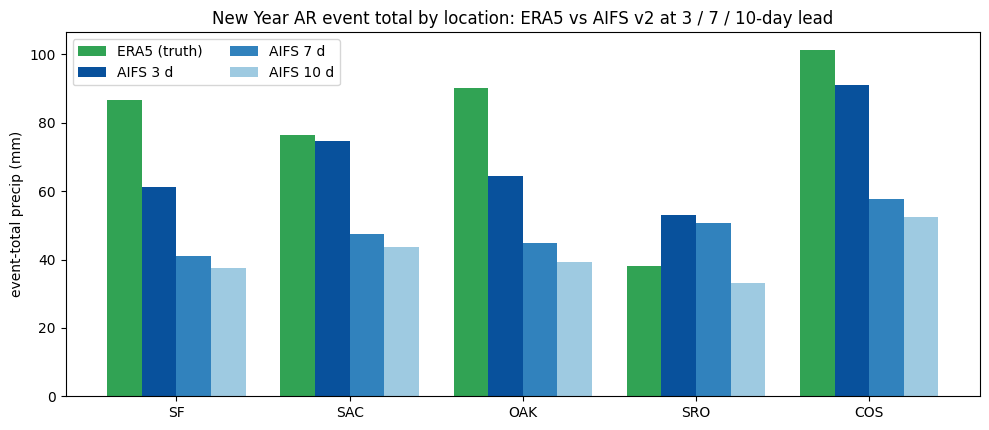

In [25]:
def event_total_at(field, lat, lon):
    '''EXACT-cell event total (Dec 31 + Jan 1) at a point, in mm. No averaging.'''
    s = at_point(field, lat, lon)
    days = s["day"].values.astype("datetime64[D]")
    sel = np.isin(days, EVENT_DAYS.astype("datetime64[D]"))
    return float(s.isel(day=np.where(sel)[0]).sum())

rows = {}
for name, (lat, lon) in LOCATIONS.items():
    era5 = round(event_total_at(era5_daily, lat, lon), 1)
    r = {"ERA5": era5}
    for L in LEAD_DAYS:
        a = round(event_total_at(aifs_daily[L], lat, lon), 1)
        r[f"AIFS {L}d"] = a
        r[f"bias {L}d"] = round(a - era5, 1)
    rows[SHORT[name]] = r
loc_event = pd.DataFrame(rows).T
loc_event.index.name = "location"
print("Event-total precip (Dec 31 + Jan 1), exact grid cell, mm:")
display(loc_event)

# grouped bar chart: ERA5 truth + AIFS at each lead, per location
labels = list(loc_event.index)
x = np.arange(len(labels))
w = 0.2
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(x - 1.5 * w, loc_event["ERA5"],     w, label="ERA5 (truth)", color="#31a354")
ax.bar(x - 0.5 * w, loc_event["AIFS 3d"],  w, label="AIFS 3 d",  color="#08519c")
ax.bar(x + 0.5 * w, loc_event["AIFS 7d"],  w, label="AIFS 7 d",  color="#3182bd")
ax.bar(x + 1.5 * w, loc_event["AIFS 10d"], w, label="AIFS 10 d", color="#9ecae1")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("event-total precip (mm)")
ax.set_title("New Year AR event total by location: ERA5 vs AIFS v2 at 3 / 7 / 10-day lead")
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "precip_eventtotal_by_location.png", dpi=110, bbox_inches="tight")
plt.show()